# Lab 2: Classification Using KNN and RNN Algorithms
**Name:** Anuj Shrestha

**Course:** MSCS 634

**Assignment:** Lab 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

In [2]:
# Load the Wine dataset from sklearn
wine = load_wine()
X, y = wine.data, wine.target
df = pd.DataFrame(X, columns=wine.feature_names)
df["target"] = y

print("Shape:", df.shape)
print("Classes:", wine.target_names)
print("\nClass distribution:")
print(df["target"].value_counts().sort_index())
df.head()

Shape: (178, 14)
Classes: ['class_0' 'class_1' 'class_2']

Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
# Feature ranges: note how different the scales are (proline vs the rest)
df.describe().T[["min", "max", "mean"]].round(2)

,min,max,mean
alcohol,11.03,14.83,13.00
malic_acid,0.74,5.80,2.34
ash,1.36,3.23,2.37
alcalinity_of_ash,10.60,30.00,19.49
magnesium,70.00,162.00,99.74
total_phenols,0.98,3.88,2.30
flavanoids,0.34,5.08,2.03
nonflavanoid_phenols,0.13,0.66,0.36
proanthocyanins,0.41,3.58,1.59
color_intensity,1.28,13.00,5.06


In [4]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (142, 13)
Testing set: (36, 13)


In [5]:
k_values = [1, 5, 11, 15, 21]
knn_acc = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)   # k nearest neighbors vote
    knn.fit(X_train, y_train)                   # train on the training set
    acc = accuracy_score(y_test, knn.predict(X_test))   # evaluate on the test set
    knn_acc.append(acc)
    print(f"k = {k:>2}  ->  accuracy = {acc:.4f}")

k =  1  ->  accuracy = 0.7778
k =  5  ->  accuracy = 0.7222
k = 11  ->  accuracy = 0.7500
k = 15  ->  accuracy = 0.7500
k = 21  ->  accuracy = 0.7778


In [6]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_acc = []

for r in radius_values:
    # outlier_label avoids an error if a test point has no neighbors within the radius
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent")
    rnn.fit(X_train, y_train)
    acc = accuracy_score(y_test, rnn.predict(X_test))
    rnn_acc.append(acc)
    print(f"radius = {r}  ->  accuracy = {acc:.4f}")

radius = 350  ->  accuracy = 0.7500
radius = 400  ->  accuracy = 0.7222
radius = 450  ->  accuracy = 0.7222
radius = 500  ->  accuracy = 0.7222
radius = 550  ->  accuracy = 0.7222
radius = 600  ->  accuracy = 0.7222


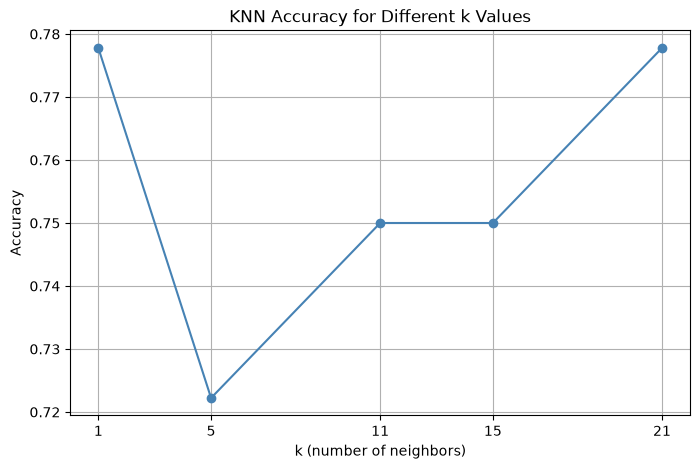

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, knn_acc, marker="o", color="steelblue")
plt.title("KNN Accuracy for Different k Values")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.grid(True)
plt.show()

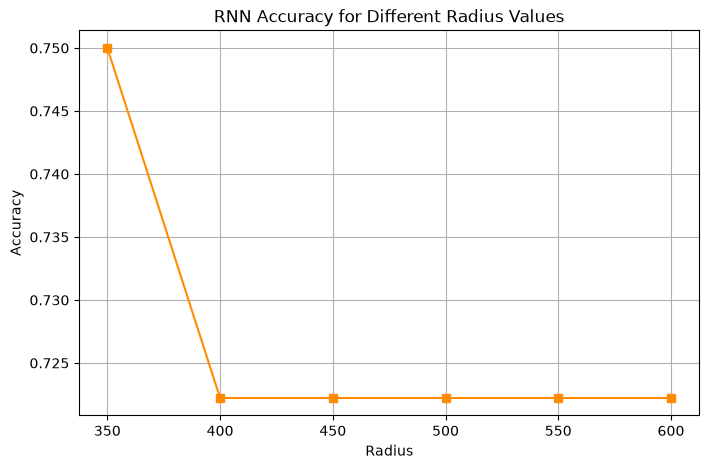

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(radius_values, rnn_acc, marker="s", color="darkorange")
plt.title("RNN Accuracy for Different Radius Values")
plt.xlabel("Radius")
plt.ylabel("Accuracy")
plt.xticks(radius_values)
plt.grid(True)
plt.show()

In [9]:
print("Best KNN: k =", k_values[int(np.argmax(knn_acc))], "| accuracy =", round(max(knn_acc), 4))
print("Best RNN: radius =", radius_values[int(np.argmax(rnn_acc))], "| accuracy =", round(max(rnn_acc), 4))

comparison = pd.DataFrame({
    "Method": ["KNN"] * len(k_values) + ["RNN"] * len(radius_values),
    "Parameter": k_values + radius_values,
    "Accuracy": knn_acc + rnn_acc
})
comparison.round(4)

Best KNN: k = 1 | accuracy = 0.7778
Best RNN: radius = 350 | accuracy = 0.75


,Method,Parameter,Accuracy
0,KNN,1,0.7778
1,KNN,5,0.7222
2,KNN,11,0.7500
3,KNN,15,0.7500
4,KNN,21,0.7778
5,RNN,350,0.7500
6,RNN,400,0.7222
7,RNN,450,0.7222
8,RNN,500,0.7222
9,RNN,550,0.7222


## Observations and Discussion

**KNN:** Accuracy stayed between 72% and 78% for every k. The best results (77.8%) came from k = 1 and k = 21, and the lowest (72.2%) from k = 5. There is no clear upward or downward trend.

**RNN:** Accuracy was highest at the smallest radius (350, 75.0%) and then stayed flat at 72.2% for all larger radii. At these radii each test sample already has many neighbors, so a bigger radius adds little new information.

**Why accuracy is modest:** The features were not scaled. Proline (about 278 to 1680) dominates the distance calculation, which is also why radii in the hundreds are needed.

**When to use which:** KNN always uses a fixed number of neighbors, so it is a safe default and easy to tune. RNN adapts to how dense the data is around a point and can flag points with no neighbors as outliers, but it depends on a well-chosen radius and works best when features are on a comparable scale.

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

for k in k_values:
    acc = accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k).fit(Xs_train, y_train).predict(Xs_test))
    print(f"scaled KNN k = {k:>2}  ->  accuracy = {acc:.4f}")

scaled KNN k =  1  ->  accuracy = 0.9444
scaled KNN k =  5  ->  accuracy = 0.9444
scaled KNN k = 11  ->  accuracy = 0.9444
scaled KNN k = 15  ->  accuracy = 0.9722
scaled KNN k = 21  ->  accuracy = 0.9444
